<a href="https://colab.research.google.com/github/afracalossi/afracalossi-afracalossi-DataScience-GenAI-Submissions/blob/main/6_02_DNN_101.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://drive.google.com/uc?export=view&id=1xqQczl0FG-qtNA2_WQYuWePW9oU8irqJ)

# 6.02 Dense Neural Network (with PyTorch)
This will expand on our logistic regression example and take us through building our first neural network. If you haven't already, be sure to check (and if neccessary) switch to GPU processing by clicking Runtime > Change runtime type and selecting GPU. We can test this has worked with the following code:

In [1]:
import torch

# Check for GPU availability
print("Num GPUs Available: ", torch.cuda.device_count())

Num GPUs Available:  1


Hopefully your code shows you have 1 GPU available! Next let's get some data. We'll start with another in-built dataset:

In [2]:
# upload an in-built Python (OK semi-in-built) dataset
from sklearn.datasets import load_diabetes

import pandas as pd
import numpy as np

# import the data
data = load_diabetes()
data

{'data': array([[ 0.03807591,  0.05068012,  0.06169621, ..., -0.00259226,
          0.01990749, -0.01764613],
        [-0.00188202, -0.04464164, -0.05147406, ..., -0.03949338,
         -0.06833155, -0.09220405],
        [ 0.08529891,  0.05068012,  0.04445121, ..., -0.00259226,
          0.00286131, -0.02593034],
        ...,
        [ 0.04170844,  0.05068012, -0.01590626, ..., -0.01107952,
         -0.04688253,  0.01549073],
        [-0.04547248, -0.04464164,  0.03906215, ...,  0.02655962,
          0.04452873, -0.02593034],
        [-0.04547248, -0.04464164, -0.0730303 , ..., -0.03949338,
         -0.00422151,  0.00306441]], shape=(442, 10)),
 'target': array([151.,  75., 141., 206., 135.,  97., 138.,  63., 110., 310., 101.,
         69., 179., 185., 118., 171., 166., 144.,  97., 168.,  68.,  49.,
         68., 245., 184., 202., 137.,  85., 131., 283., 129.,  59., 341.,
         87.,  65., 102., 265., 276., 252.,  90., 100.,  55.,  61.,  92.,
        259.,  53., 190., 142.,  75., 142.

We are working on a regression problem, with "structured" data which has already been cleaned and normalised. We can skip the usual cleaning/engineering steps. However, we do need to get the data into PyTorch:

In [3]:
# Convert data to PyTorch tensors
X = torch.tensor(data.data, dtype=torch.float32)
y = torch.tensor(data.target, dtype=torch.float32).reshape(-1, 1) # Reshape y to be a column vector

Now our data is stored in tensors we can do train/test splitting as before (in fact we can use sklearn as before):

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

torch.Size([353, 10]) torch.Size([353, 1])
torch.Size([89, 10]) torch.Size([89, 1])


Now we can set up our batches for training. As we have a nice round 400 let's go with batches of 50 (8 batches in total). We'll also seperate the features and labels:

In [5]:
from torch.utils.data import TensorDataset, DataLoader

# Create TensorDatasets and DataLoaders
train_dataset = TensorDataset(X_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=50, shuffle=True)

test_dataset = TensorDataset(X_test, y_test)
test_loader = DataLoader(test_dataset, batch_size=50, shuffle=False)

Now its time to build our model. We'll keep it simple ... a model with an input layer of 10 features and then 2x _Dense_ (fully connected) layers each with 5 neurons and ReLU activation. Our output layer will be size=1 given this is a regression problem and we want a single value output per prediction.

This will be easier to understand if you have read through the logistic regression tutorial.

In [6]:
import torch
import torch.nn as nn

# Define the model
class DiabetesModel(nn.Module):
    def __init__(self):
        super(DiabetesModel, self).__init__()
        # we'll set up the layers as a sequence using nn.Sequential
        self.layers = nn.Sequential(

            # first layer will be a linear layer that has 5x neurons
            # (5x sets of linear regression)
            # the layer takes the 10 features as input (i.e. 10, 5)
            nn.Linear(10, 5),

            nn.ReLU(), # ReLU activation

            # second linear layer again has 5 neurons
            # this time taking the input as the output of the last layer
            # (which had 5x neurons)
            nn.Linear(5, 5),

            nn.ReLU(), # ReLU again

            # last linear layer takes the output from the previous 5 neurons
            # this time its a single output with no activation
            # i.e. this is the predicitons (regression)
            nn.Linear(5, 1)
        )

    def forward(self, x):
        return self.layers(x) # pass the data through the layers

As before we need to create a model object, specify the loss (criterion) and an optimiser (which we cover next week):

In [7]:
import torch.optim as optim

# Initialize the model, loss function, and optimizer
model = DiabetesModel()
criterion = nn.MSELoss() # MSE loss function
optimiser = optim.Adam(model.parameters(), lr=0.001)

Now we can train the model. Again, the logistic regression tutorial (6.01) may help you undertstand this:

In [12]:
# Move model to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Training loop (example - you'll likely want to add more epochs)
epochs = 1000 # 100 epochs

for epoch in range(epochs):
  # use the train_loader to pass the inputs (x) and targets (y)
  for inputs, targets in train_loader:
    # pass to the GPU (hopefully)
    inputs, targets = inputs.to(device), targets.to(device)

    # pass model to GPU as well
    model.to(device)

    model.train() # put the model object in train mode
    optimiser.zero_grad() # reset the gradiants
    outputs = model(inputs) # create outputs
    loss = criterion(outputs, targets) # compare with Y to get loss
    loss.backward() # backpropogate the loss (next week)
    optimiser.step() # # update the parameters based on this round of training

  # every 10 steps we will print out the current loss
    if (epoch+1) % 10 == 0: # modular arithmetic
        print(f'Epoch [{epoch+1}/{epochs}], Loss: {round(loss.item(), 4)}')

Epoch [10/1000], Loss: 3243.51
Epoch [10/1000], Loss: 2525.7756
Epoch [10/1000], Loss: 2913.9131
Epoch [10/1000], Loss: 3342.0625
Epoch [10/1000], Loss: 3486.1223
Epoch [10/1000], Loss: 2558.208
Epoch [10/1000], Loss: 2368.4072
Epoch [10/1000], Loss: 443.5894
Epoch [20/1000], Loss: 2959.5618
Epoch [20/1000], Loss: 2565.9932
Epoch [20/1000], Loss: 3314.8057
Epoch [20/1000], Loss: 2268.6477
Epoch [20/1000], Loss: 3617.613
Epoch [20/1000], Loss: 2320.8057
Epoch [20/1000], Loss: 3142.6306
Epoch [20/1000], Loss: 4346.5156
Epoch [30/1000], Loss: 4087.3516
Epoch [30/1000], Loss: 2676.0229
Epoch [30/1000], Loss: 2795.959
Epoch [30/1000], Loss: 2039.1073
Epoch [30/1000], Loss: 2994.6943
Epoch [30/1000], Loss: 2936.2388
Epoch [30/1000], Loss: 2658.7168
Epoch [30/1000], Loss: 4554.3525
Epoch [40/1000], Loss: 2666.1143
Epoch [40/1000], Loss: 2084.2603
Epoch [40/1000], Loss: 2807.8037
Epoch [40/1000], Loss: 3657.1675
Epoch [40/1000], Loss: 2920.575
Epoch [40/1000], Loss: 2772.2825
Epoch [40/1000], 

We can see loss is significantly lower at the end than it was at the start. However, it is also bouncing around a little still which suggests the model needs more training (100 epochs is not a lot in deep learning terms). However, let's evaluate as before:

In [13]:
# Evaluation (example)
model.eval() # testing mode
mse_values = [] # collect the MSE scores

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = model(inputs) # predict the test data

        # Calculate Mean Squared Error
        mse = criterion(outputs, targets) # calcualte mse for the batch
        mse_values.append(mse.item()) # add to the list of MSE values

# Calculate and print the average MSE
avg_mse = np.mean(mse_values)
print(f"Average MSE on test set: {avg_mse}")

Average MSE on test set: 2869.1298828125


MSE looks expected given training (no obvious sign of overfitting). However, we probably can get better results with tuning and more epochs.

Let's run the loop again a little differently to collect the predicted values (y_hat) and actuals (y) and add them to a dataset for comparions:

In [14]:
# Evaluation
model.eval()
predictions = []
actuals = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = model(inputs)
        predictions.extend(outputs.cpu().numpy())
        actuals.extend(targets.cpu().numpy())

# Create DataFrame
results_df = pd.DataFrame({'Predicted': np.array(predictions).flatten(), 'Actual': np.array(actuals).flatten()})
results_df

,Predicted,Actual
0,140.499130,219.0
1,180.617905,70.0
2,139.656616,202.0
3,293.638733,230.0
4,120.164352,111.0
...,...,...
84,110.522491,153.0
85,84.445526,98.0
86,79.924065,37.0
87,61.530670,63.0


Side-by-side, they don't look great. Can you improve them?

<br><br>

## EXERCISE #1
Try increasing the number of epochs to 1,000 (when the model is fairly well trained then the results printed for each 10x epochs will be fairly stable and not change much). Does this give better results?

Yes we can see the predictions are much closer to the results now, yet still not perfect

<br><br>

## EXERCISE #2 (optional)
Try experimenting with the architecture (number of neurons and/or number of layers). Can we reach an optimal architecture?

## EXERCISE #2: Improving the Model Architecture

Let's design a higher-capacity neural network called `ImprovedDiabetesModel` with the following changes:
1. **Wider layers**: Increase the number of neurons from 5 to 64 and 32.
2. **Deeper architecture**: Add an extra fully-connected layer.
3. **Regularization (Optional)**: If you notice overfitting, we can add Dropout layers, but since this is a relatively simple dataset, we'll start with a clean fully-connected network to see if it learns the patterns better than our 5-neuron baseline.

In [15]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd

# Define a deeper and wider model
class ImprovedDiabetesModel(nn.Module):
    def __init__(self):
        super(ImprovedDiabetesModel, self).__init__()
        self.layers = nn.Sequential(
            # Input layer: 10 features -> 64 neurons
            nn.Linear(10, 64),
            nn.ReLU(),

            # Hidden layer 1: 64 -> 32 neurons
            nn.Linear(64, 32),
            nn.ReLU(),

            # Hidden layer 2: 32 -> 16 neurons
            nn.Linear(32, 16),
            nn.ReLU(),

            # Output layer: 16 -> 1 prediction
            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.layers(x)


In [16]:
# Initialize the improved model, loss, and optimizer
improved_model = ImprovedDiabetesModel().to(device)
criterion = nn.MSELoss()

# Using a slightly higher capacity model, we can try a learning rate of 0.003
optimizer = optim.Adam(improved_model.parameters(), lr=0.003)

epochs = 1000

for epoch in range(epochs):
    improved_model.train()
    for inputs, targets in train_loader:
        inputs, targets = inputs.to(device), targets.to(device)

        optimizer.zero_grad()
        outputs = improved_model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

    if (epoch + 1) % 100 == 0:
        print(f'Epoch [{epoch+1}/{epochs}], Loss: {round(loss.item(), 4)}')


Epoch [100/1000], Loss: 3225.5273
Epoch [200/1000], Loss: 4006.5515
Epoch [300/1000], Loss: 1233.9276
Epoch [400/1000], Loss: 1949.1211
Epoch [500/1000], Loss: 4307.5293
Epoch [600/1000], Loss: 1755.5088
Epoch [700/1000], Loss: 3195.7681
Epoch [800/1000], Loss: 5290.353
Epoch [900/1000], Loss: 2776.3074
Epoch [1000/1000], Loss: 1457.2885


In [19]:
# Evaluate the improved model
improved_model.eval()
improved_mse_values = []
improved_predictions = []
improved_actuals = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = improved_model(inputs)

        mse = criterion(outputs, targets)
        improved_mse_values.append(mse.item())

        improved_predictions.extend(outputs.cpu().numpy())
        improved_actuals.extend(targets.cpu().numpy())

print(f"Baseline Average MSE: {avg_mse}")
print(f"Improved Average MSE: {np.mean(improved_mse_values)}")

# Create DataFrame with the CORRECT improved predictions
results_df = pd.DataFrame({
    'Improved Predicted': np.array(improved_predictions).flatten(),
    'Actual': np.array(improved_actuals).flatten()
})
results_df

Baseline Average MSE: 2869.1298828125
Improved Average MSE: 2571.016357421875


,Improved Predicted,Actual
0,144.558792,219.0
1,189.147995,70.0
2,144.432083,202.0
3,316.955383,230.0
4,115.320572,111.0
...,...,...
84,109.104950,153.0
85,82.822815,98.0
86,98.292931,37.0
87,81.881210,63.0


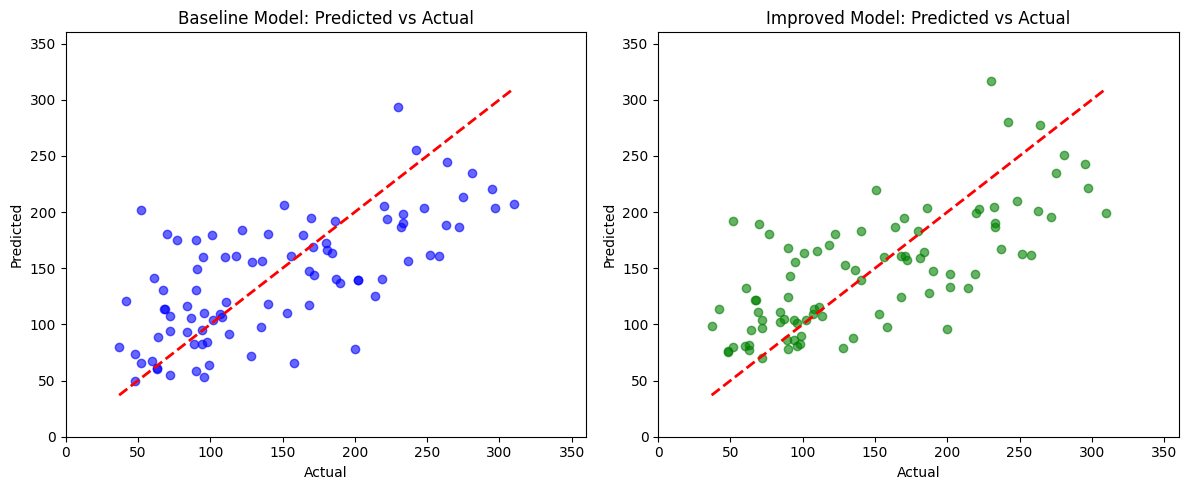

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Baseline predictions plot
plt.subplot(1, 2, 1)
plt.scatter(actuals, predictions, alpha=0.6, color='blue')
plt.plot([min(actuals), max(actuals)], [min(actuals), max(actuals)], 'r--', lw=2)
plt.title('Baseline Model: Predicted vs Actual')
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.xlim(0, 360)
plt.ylim(0, 360)

# Improved predictions plot
plt.subplot(1, 2, 2)
plt.scatter(improved_actuals, improved_predictions, alpha=0.6, color='green')
plt.plot([min(improved_actuals), max(improved_actuals)], [min(improved_actuals), max(improved_actuals)], 'r--', lw=2)
plt.title('Improved Model: Predicted vs Actual')
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.xlim(0, 360)
plt.ylim(0, 360)

plt.tight_layout()
plt.show()